In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split 

SEED = 42 

FEATURE_COLS = ["Age", "Weight_kg", "Height_m", "Max_BPM", "Avg_BPM"
                , "Resting_BPM", "Session_Duration_min", "Fat_Percentage", "Water_Intake_liters", "BMI"] 

# the notebook is inside notebooks/, so the csv is one folder up 
df = pd.read_csv("../backend/data/gym_members_clean.csv") 

# same split for everyone in the team: 80% train / 20% test 
Xtr, Xte, yc_tr, yc_te, yr_tr, yr_te = train_test_split( 
    df[FEATURE_COLS], df["Overtraining_Risk_Label"], df["Calories_Burned"], 
    test_size=0.2, random_state=SEED, stratify=df["Overtraining_Risk_Label"]) 

print(Xtr.shape, Xte.shape)   # (778, 10) (195, 10)

(778, 10) (195, 10)


In [11]:
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

# printing label percentage (1 => overtraining risk, 0 => normal)
print(yc_tr.value_counts(normalize=True))

# scaling 
scaler = StandardScaler()
Xtr_scaled = scaler.fit_transform(Xtr)
Xte_scaled = scaler.transform(Xte)

# detecting anomalies (IsolationForest)
iso = IsolationForest(contamination=0.06, random_state=SEED)
iso_predictions = iso.fit_predict(Xtr_scaled)

anomalies = (iso_predictions == -1).sum()
print("\nDetected Anomalies in Traing Set: ", anomalies)

anomalies_df = Xtr[iso_predictions == -1]
normal_df = Xtr[iso_predictions == 1]

# anomalies vs normal points
comparison = pd.DataFrame({
    "Anomalies Mean" : anomalies_df.mean(),
    "Normal Mean" : normal_df.mean()
})

print(comparison)

Overtraining_Risk_Label
1    0.650386
0    0.349614
Name: proportion, dtype: float64

Detected Anomalies in Traing Set:  47
                      Anomalies Mean  Normal Mean
Age                        37.404255    38.844049
Weight_kg                  96.314894    72.166484
Height_m                    1.767234     1.719699
Max_BPM                   179.936170   179.906977
Avg_BPM                   147.489362   143.467852
Resting_BPM                62.085106    62.114911
Session_Duration_min       67.429787    75.598358
Fat_Percentage             22.214894    25.287004
Water_Intake_liters         2.861702     2.607934
BMI                        31.434255    24.426990


In [52]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

# dummy classifier
dummy_clf = DummyClassifier(strategy="most_frequent", random_state=SEED)
dummy_clf.fit(Xtr_scaled, yc_tr)
y_pred_dummy = dummy_clf.predict(Xte_scaled)
y_prob_dummy = dummy_clf.predict_proba(Xte_scaled)[:,1]

print("\n==========Dummy Classifier Metrics============")
print("F1 Score: ", f1_score(yc_te, y_pred_dummy))
print("Confution Matrix:\n ", confusion_matrix(yc_te, y_pred_dummy))

#----------------------------------------------------------------

# decision tree classifier
dt_clf = DecisionTreeClassifier(max_depth=3, random_state=SEED)
dt_clf.fit(Xtr_scaled, yc_tr)
y_pred_dt = dt_clf.predict(Xte_scaled)
y_prob_dt = dt_clf.predict_proba(Xte_scaled)[:,1]

print("\n==========Decision Tree Metrics==============")
print("F1 Score: ", f1_score(yc_te, y_pred_dt))
print("AUC: ", roc_auc_score(yc_te, y_prob_dt))
print("Confution Matrix:\n ", confusion_matrix(yc_te, y_pred_dt))

#----------------------------------------------------------------

# random forest classifier
rf_clf = RandomForestClassifier(n_estimators=200, max_depth=12, class_weight="balanced", random_state=SEED)
rf_clf.fit(Xtr_scaled, yc_tr)
y_pred_rf = rf_clf.predict(Xte_scaled)
y_prob_rf = rf_clf.predict_proba(Xte_scaled)[:,1]

print("\n==========Random Forest Metrics==============")
print("F1 Score: ", f1_score(yc_te, y_pred_rf))
print("AUC: ", roc_auc_score(yc_te, y_prob_rf))
print("Confution Matrix:\n ", confusion_matrix(yc_te, y_pred_rf))

importances = rf_clf.feature_importances_
importances_df = pd.DataFrame({
    "Feature" : FEATURE_COLS,
    "Importance" : importances
}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

importances_df.index += 1

print("\n==========Feature Imporatnce=================")
print(importances_df.head(5))


==========Dummy Classifier Metrics============
F1 Score:  0.7888198757763976
Confution Matrix:
  [[  0  68]
 [  0 127]]

==========Decision Tree Metrics==============
F1 Score:  0.9126984126984127
AUC:  0.9309865678554887
Confution Matrix:
  [[ 58  10]
 [ 12 115]]

==========Random Forest Metrics==============
F1 Score:  0.944
AUC:  0.9773043075497916
Confution Matrix:
  [[ 63   5]
 [  9 118]]

==========Feature Imporatnce=================
                Feature  Importance
1               Max_BPM    0.384640
2                   Age    0.380501
3               Avg_BPM    0.036425
4  Session_Duration_min    0.032584
5        Fat_Percentage    0.030519


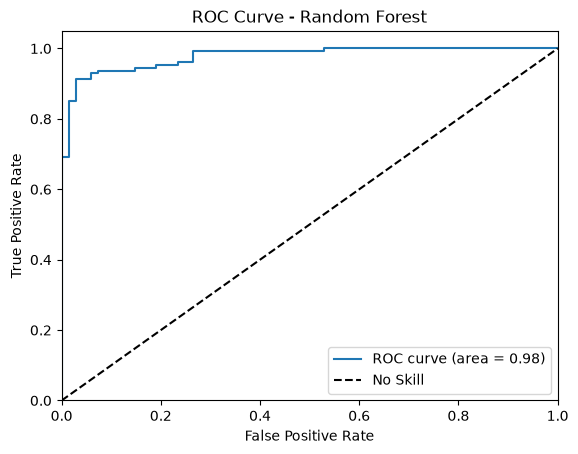

In [ ]:
# calculate ROC curve for random forest 
fpr, tpr, thresholds = roc_curve(yc_te, y_prob_rf) 
roc_auc = roc_auc_score(yc_te, y_prob_rf)

# plot the ROC curve
plt.figure()  
plt.plot(fpr, tpr, label="ROC curve (area = %0.2f)" % roc_auc)
plt.plot([0, 1], [0, 1], "k--", label="No Skill")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FP)")
plt.ylabel("True Positive Rate (TP)")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.show()

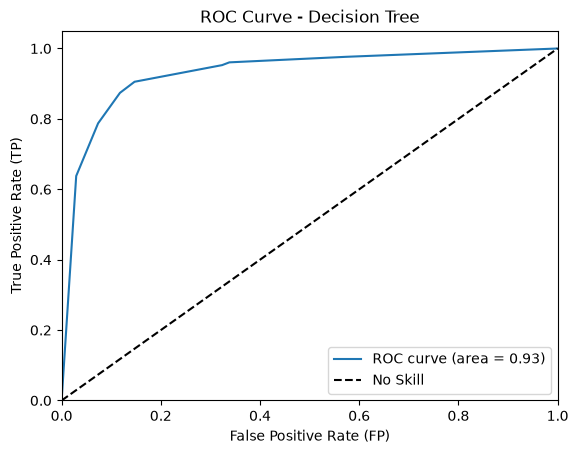

In [51]:
# calculate ROC curve for decision tree 
fpr, tpr, thresholds = roc_curve(yc_te, y_prob_dt) 
roc_auc = roc_auc_score(yc_te, y_prob_dt)

# plot the ROC curve
plt.figure()  
plt.plot(fpr, tpr, label="ROC curve (area = %0.2f)" % roc_auc)
plt.plot([0, 1], [0, 1], "k--", label="No Skill")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FP)")
plt.ylabel("True Positive Rate (TP)")
plt.title("ROC Curve - Decision Tree")
plt.legend()
plt.show()

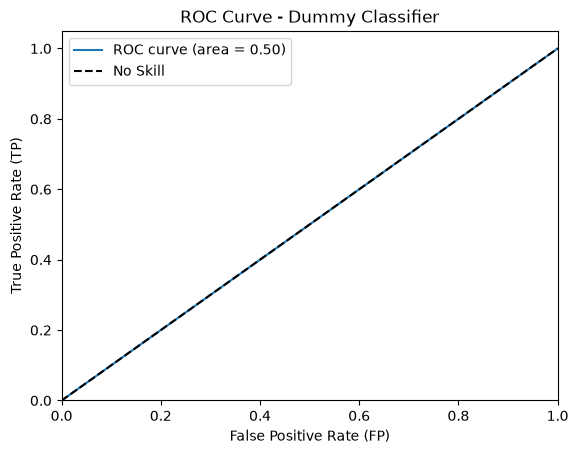

In [53]:
# calculate ROC curve for Dummy Classifier
fpr, tpr, thresholds = roc_curve(yc_te, y_prob_dummy) 
roc_auc = roc_auc_score(yc_te, y_prob_dummy)

# plot the ROC curve
plt.figure()  
plt.plot(fpr, tpr, label="ROC curve (area = %0.2f)" % roc_auc)
plt.plot([0, 1], [0, 1], "k--", label="No Skill")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate (FP)")
plt.ylabel("True Positive Rate (TP)")
plt.title("ROC Curve - Dummy Classifier")
plt.legend()
plt.show()

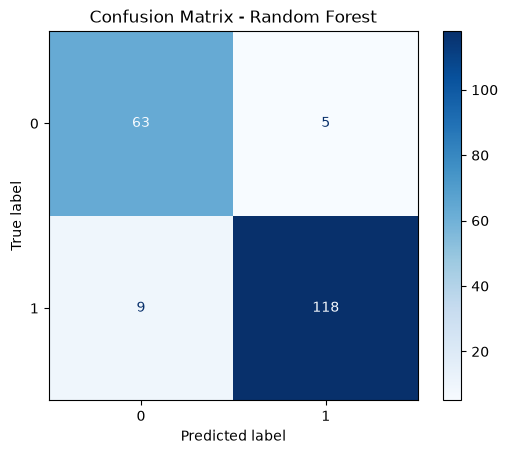

In [54]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(yc_te, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=cm , display_labels=[0, 1])
disp.plot(cmap= plt.cm.Blues)
plt.title("Confusion Matrix - Random Forest")
plt.show()

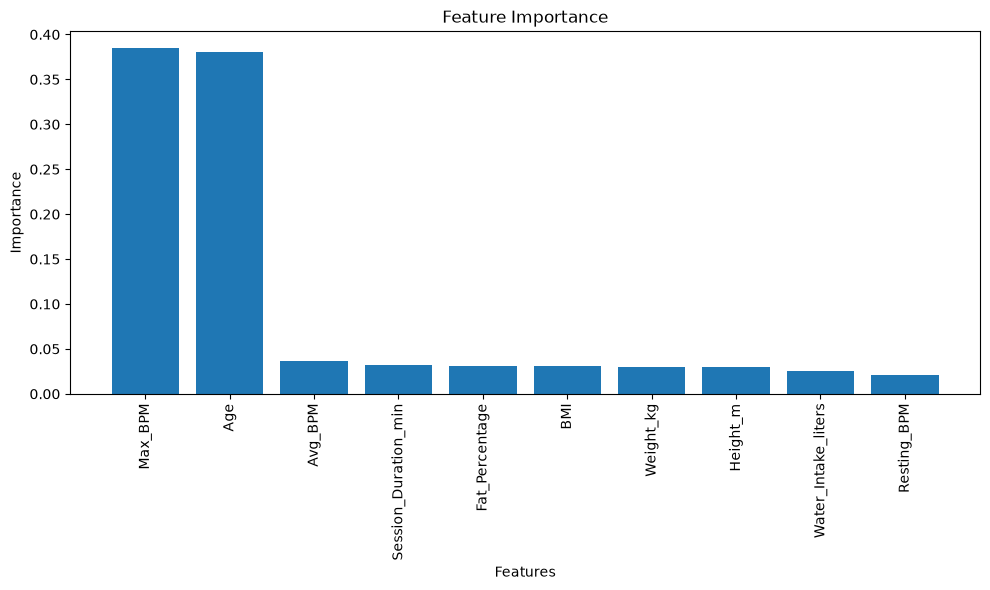

In [58]:
indices = np.argsort(importances)[::-1]
names = [FEATURE_COLS[i] for i in indices]

plt.figure(figsize=(10, 6))
plt.title("Feature Importance")
plt.bar(range(Xtr_scaled.shape[1]), importances[indices])
plt.xticks(range(Xtr_scaled.shape[1]), names, rotation=90)
plt.xlabel("Features")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()
